In [1]:
from IPython.display import Image

- references
    - https://dilithjay.com/blog/q-learning-and-sarsa
- target policy vs. behavior policy
    - target policy：作为评估和改进对象的策略
    - behavior policy：采取行动的策略，产生 $(s,a,r)$ 样本数据的策略
- on-policy vs. off-policy
    - "用于评估和改进的目标策略"与"用于实际行动的行为策略"为同样的策略：on-policy
    - 反之则为 off-policy
        - 只让行为策略进行探索，只让目标策略进行利用

### IS (Importance Sampling) 

> 重要性采样利用从其他概率分布中采样的数据来计算某个概率分布的期望值。
- 从行为策略获得的样本数据来求目标策略的期望值，此时用到的即为重要性采样；
- 两分并越接近，估计的方差越小；

### SARSA vs. Q-learning

> SARSA 和 Q-learning 都是 TD 学习的具体算法。它们唯一的区别在于 如何构建 TD 目标值，也就是如何估计下一步的价值。

$$
Q(S_t,A_t)\leftarrow Q(S_t,A_t)+\alpha(\underbrace{R_{t+1}+\gamma Q(S_{t+1},A_{t+1})}_{\text{TD target}}-Q(S_t,A_t)
$$

- 直观对比二者的流程：核心在于 $A_{t+1}$ 的选择
    - SARSA 的工作流程（一个时间步）
        - 第1步：在状态 S_t 做决策
            - 你当前处于状态 S_t。
            - 你根据你当前的策略（比如 ε-greedy 策略，它有一定概率会随机探索，有很大概率会选择当前认为最优的动作），选择了一个动作 A_t。
        - 第2步：执行动作并观察结果
            - 你执行动作 A_t。
            - 环境发生变化，你获得了一个即时奖励 R_{t+1}，并且进入了下一个状态 S_{t+1}。
        - 第3步：在新的状态 S_{t+1} 准备下一个决策（这是关键！）
            - 现在，你已经身处全新的状态 S_{t+1}。
            - 你需要决定下一步要干什么。于是，你再次使用你的策略（**和第1步中完全相同的策略**），在 S_{t+1} 这个状态下，选择出了你将要执行的下一个动作 A_{t+1}。
                - 选择 $A_t, A_{t+1}$ 是同一个策略
        - 第4步：回顾与更新
            - 好了，到此为止，你已经集齐了更新所需的所有要素，形成了一个完整的序列：
                - (状态 S_t, 动作 A_t, 奖励 R_{t+1}, 下一个状态 S_{t+1}, 下一个动作 A_{t+1})
            - 这就是 SARSA 这个名字的由来。
            - 现在，你用这个完整的序列，回头去更新你在第1步做的那个决策的价值，也就是 Q(S_t, A_t)。
            - 你用来更新的公式中的 Q(S_{t+1}, A_{t+1})，使用的就是你在第3步中实际选择出来、并准备在下一步执行的那个动作 A_{t+1}。
    - 至于 Q-learning
        - $Q(S_t,A_t)\leftarrow Q(S_t,A_t)+\alpha(R_{t+1}+\gamma\max_aQ(S_{t+1},a)-Q(S_t,A_t))$
        - 它在更新 Q(S_t, A_t) 时，它不关心 在 S_{t+1} 状态下，根据当前策略实际会选择哪个动作。相反，它会环顾 S_{t+1} 状态下的所有可能动作，然后挑选出那个能带来最大Q值的动作 $\max_a Q(S_t,a)$，，并用这个最乐观、最理想化的价值来构建 TD 目标。
        - 它的“内心独白”是：“我不管我下一步实际上会怎么走（可能因为探索我会走一步臭棋），我在评估过去时，永远都假设我下一步会做出最完美的选择。”
        - 这就是为什么 Q-learning 是 离策略（Off-policy） 的。它用于评估的策略（永远取 max）和它用于执行动作的策略（ε-greedy）可以是不同的。它学习的是一条通往最优目标的捷径，哪怕它自己当前还在蹒跚学步、到处乱撞。

In [2]:
Image(url='https://static.mofanpy.com/static/results/ML-intro/s4.png?t=68a5e746&sign=219fec391afb06b972c876c7f49d6a6f', width=500)

- $(s,a)$, $r$, $(s',a')$
    - $Q(s,a)$ 的更新取决于两组pair，$s_t,a_t$ 以及 $s_{t+1},a'$

### coding

In [13]:
Image(url='https://dilithjay.com/assets/images/q-vs-sarsa.webp', width=400)

- Sarsa的保守行为正是源于其同策略的更新机制，这在带有探索（Exploration）的训练过程中尤为明显。在“悬崖行走”问题中：
    - 探索的风险被纳入考量： 为了找到最优解，智能体通常会采用$\epsilon$-greedy等策略，即有$\epsilon$的概率会随机选择一个动作，而不是当前认为最优的动作。对于紧邻悬崖的格子，即使最优动作是“向右”，随机探索也可能导致智能体选择“向下”的动作，从而掉下悬崖，并获得巨大的负奖励（例如-100）。
    - Sarsa的“实事求是”更新： 由于Sarsa是同策略的，它在更新Q值时，会使用下一步实际采取的动作 $A_{t+1}$ 。如果因为$\epsilon$-greedy策略，智能体在悬崖边随机向下走了一步掉入悬崖，那么这个巨大的负奖励就会被用来更新前一步（悬崖边格子的“向右”动作）的Q值。经过多次这样的尝试，Sarsa会逐渐认识到，即使悬崖边的理论最优路径回报很高，但实际执行时伴随着巨大的风险。因此，它会降低紧贴悬崖路径上所有状态-动作对的Q值。
    - Q-learning的“理想主义”更新： 与之相反，Q-learning在更新时采用的是 $\max_aQ(S_{t+1} ,a)$。这意味着，无论下一步因为探索实际走了哪一步（即使是掉下悬崖），Q-learning在计算当前Q值时，总是乐观地假设下一步会执行最优动作（即继续向右走）。因此，掉下悬崖的负面经验不会直接影响到它对最优路径（红色路线）价值的评估。它学到的是一条“只要不失误，就是最快”的路径。
- sarsa 的风险污染
    - 如果它到了s'后，下一步实际走了“下”，那么在更新Q(s, "右")时，它的信息来源就直接是那个很差的Q(s', "下")的值，这就造成了“风险污染”。
    - 而对于 q-learning，Q-learning的max更新规则在计算Q(s, "右")的新值时，其信息来源（s'行的最大Q值）天然地屏蔽了Q(s', "下")那个可能很差的值。
- curve
    - Q-learning：平均奖励较低且方差大，因为在探索最优路径时会频繁掉下悬崖。
    - SARSA：平均奖励较高且方差小，因为其谨慎的策略成功地避开了悬崖和灾难性的惩罚。

In [46]:
import torch
import numpy as np
import matplotlib.pyplot as plt

class CliffWalkingEnv:
    def __init__(self, width=12, height=4):
        self.width = width
        self.height = height
        self.start_pos = (height - 1, 0)
        self.goal_pos = (height - 1, width - 1)

        # 定义悬崖区域
        self.cliff = [(height - 1, x) for x in range(1, width - 1)]

        # 动作空间: 0:上, 1:下, 2:左, 3:右
        self.action_space = [0, 1, 2, 3]
        self.action_map = {
            0: (-1, 0),  # Up
            1: (1, 0),   # Down
            2: (0, -1),  # Left
            3: (0, 1)    # Right
        }
        
        self.state = self.start_pos

    def reset(self):
        """重置环境到初始状态"""
        self.state = self.start_pos
        return self.state

    def step(self, action):
        """执行一个动作"""
        y, x = self.state
        dy, dx = self.action_map[action]
        
        # 计算新位置，并确保不越界
        next_y = max(0, min(self.height - 1, y + dy))
        next_x = max(0, min(self.width - 1, x + dx))
        
        self.state = (next_y, next_x)
        
        reward = -1  # 每走一步的默认惩罚
        done = False

        if self.state == self.goal_pos:
            reward = 0  # 到达终点没有惩罚
            done = True
        elif self.state in self.cliff:
            reward = -100 # 掉下悬崖
            done = True # 在我们的实现中，掉下悬崖也算一个 episode 结束
            self.state = self.start_pos # 重置到起点
            
        return self.state, reward, done

    def state_to_int(self, state_tuple):
        """将 (y, x) 坐标转换为唯一的整数状态"""
        return state_tuple[0] * self.width + state_tuple[1]

    def int_to_state(self, state_int):
        """将整数状态转换回 (y, x) 坐标"""
        y = state_int // self.width
        x = state_int % self.width
        return (y, x)

In [37]:
class BaseAgent:
    def __init__(self, env, alpha=0.1, gamma=0.99, epsilon=0.1):
        self.env = env
        self.num_states = env.height * env.width
        self.num_actions = len(env.action_space)
        
        # 使用 PyTorch Tensor 来创建 Q-Table
        self.q_table = torch.zeros((self.num_states, self.num_actions), dtype=torch.float32)
        
        self.alpha = alpha  # 学习率
        self.gamma = gamma  # 折扣因子
        self.epsilon = epsilon # epsilon-greedy 策略的探索率

    def choose_action(self, state):
        """使用 epsilon-greedy 策略选择动作"""
        state_idx = self.env.state_to_int(state)
        if torch.rand(1).item() < self.epsilon:
            # 探索：随机选择一个动作
            return np.random.choice(self.env.action_space)
        else:
            # 利用：选择Q值最高的动作
            return torch.argmax(self.q_table[state_idx]).item()
            
    def get_path(self):
        """从Q-Table中提取最优路径"""
        path = []
        state = self.env.reset()
        path.append(state)
        done = False
        
        while not done:
            state_idx = self.env.state_to_int(state)
            action = torch.argmax(self.q_table[state_idx]).item()
            state, _, done = self.env.step(action)
            path.append(state)
            if len(path) > 50: # 防止死循环
                print("路径过长，可能未能收敛")
                break
        return path

class QLearningAgent(BaseAgent):
    def update(self, state, action, reward, next_state):
        state_idx = self.env.state_to_int(state)
        next_state_idx = self.env.state_to_int(next_state)
        
        # Q-Learning 更新规则
        q_predict = self.q_table[state_idx, action]
        
        # 核心差异：使用 max Q(s', a')
        q_target = reward + self.gamma * torch.max(self.q_table[next_state_idx])
        
        self.q_table[state_idx, action] += self.alpha * (q_target - q_predict)

class SarsaAgent(BaseAgent):
    def update(self, state, action, reward, next_state, next_action):
        state_idx = self.env.state_to_int(state)
        next_state_idx = self.env.state_to_int(next_state)
        
        # SARSA 更新规则
        q_predict = self.q_table[state_idx, action]

        # 核心差异：使用 Q(s', a')，其中 a' 是下一个实际要执行的动作
        q_target = reward + self.gamma * self.q_table[next_state_idx, next_action]
        
        self.q_table[state_idx, action] += self.alpha * (q_target - q_predict)

In [38]:
def train(agent, episodes=500):
    episode_rewards = []
    agent_name = agent.__class__.__name__
    print(f"--- 开始训练 {agent_name} ---")
    
    for episode in range(episodes):
        state = agent.env.reset()
        done = False
        total_reward = 0
        
        # SARSA 需要先选择第一个动作
        action = agent.choose_action(state)
        
        while not done:
            next_state, reward, done = agent.env.step(action)
            total_reward += reward
            
            if isinstance(agent, QLearningAgent):
                agent.update(state, action, reward, next_state)
                state = next_state
                action = agent.choose_action(state) # 为下一次循环选择动作
            
            elif isinstance(agent, SarsaAgent):
                # SARSA 需要知道下一个状态的下一个动作
                next_action = agent.choose_action(next_state)
                agent.update(state, action, reward, next_state, next_action)
                state = next_state
                action = next_action
        
        episode_rewards.append(total_reward)
        if (episode + 1) % 200 == 0:
            print(f"Episode {episode + 1}/{episodes}, Total Reward: {total_reward}")
            
    return episode_rewards

def print_path_on_grid(env, path):
    """在网格上打印路径"""
    grid = np.full((env.height, env.width), " ", dtype=str)
    grid[env.start_pos] = 'S'
    grid[env.goal_pos] = 'G'
    for r, c in env.cliff:
        grid[r, c] = 'C'
    
    for i in range(1, len(path)-1):
        y, x = path[i]
        prev_y, prev_x = path[i-1]
        
        if y < prev_y: grid[y, x] = '↑'
        elif y > prev_y: grid[y, x] = '↓'
        elif x < prev_x: grid[y, x] = '←'
        elif x > prev_x: grid[y, x] = '→'
        
    print("\n学到的路径:")
    for row in grid:
        print(" ".join(row))

In [39]:
import numpy as np
# Define a function for moving average
def moving_average(data, window_size):
  """Computes the moving average of a 1D array."""
  return np.convolve(data, np.ones(window_size), 'valid') / window_size

--- 开始训练 QLearningAgent ---
Episode 200/3000, Total Reward: -29
Episode 400/3000, Total Reward: -12
Episode 600/3000, Total Reward: -12
Episode 800/3000, Total Reward: -12
Episode 1000/3000, Total Reward: -13
Episode 1200/3000, Total Reward: -14
Episode 1400/3000, Total Reward: -12
Episode 1600/3000, Total Reward: -12
Episode 1800/3000, Total Reward: -16
Episode 2000/3000, Total Reward: -14
Episode 2200/3000, Total Reward: -14
Episode 2400/3000, Total Reward: -103
Episode 2600/3000, Total Reward: -100
Episode 2800/3000, Total Reward: -12
Episode 3000/3000, Total Reward: -13
--- 开始训练 SarsaAgent ---
Episode 200/3000, Total Reward: -21
Episode 400/3000, Total Reward: -16
Episode 600/3000, Total Reward: -14
Episode 800/3000, Total Reward: -16
Episode 1000/3000, Total Reward: -18
Episode 1200/3000, Total Reward: -14
Episode 1400/3000, Total Reward: -17
Episode 1600/3000, Total Reward: -100
Episode 1800/3000, Total Reward: -19
Episode 2000/3000, Total Reward: -16
Episode 2200/3000, Total Rew

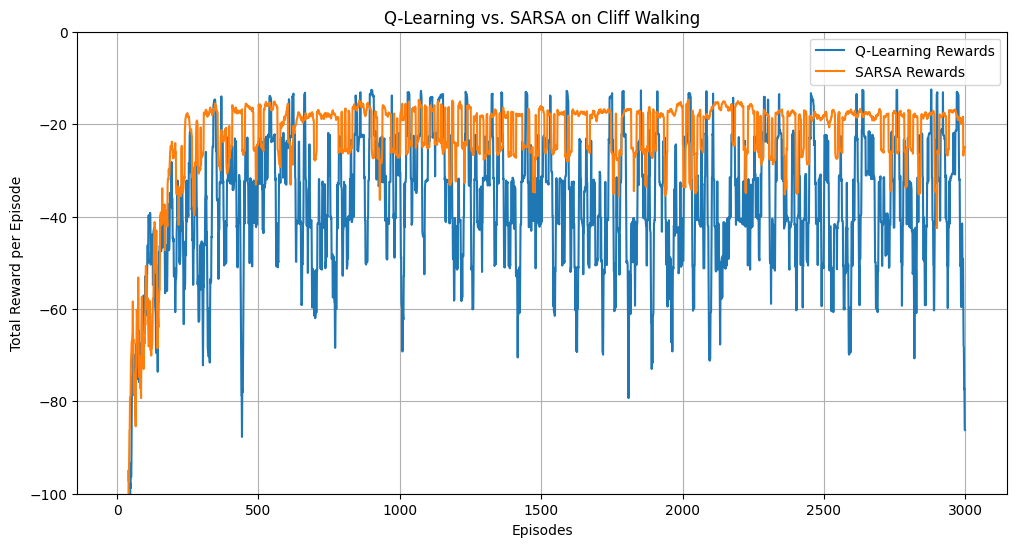


Q-Learning (离策略) 的结果

学到的路径:
                       
                       
↑ → → → → → → → → → → →
S C C C C C C C C C C G

SARSA (同策略) 的结果

学到的路径:
↑ → → → → → → → → → → →
↑                     ↓
↑                     ↓
S C C C C C C C C C C G


In [47]:

# 初始化环境和智能体
env = CliffWalkingEnv()
q_agent = QLearningAgent(env, alpha=0.1, gamma=0.9, epsilon=0.1)
sarsa_agent = SarsaAgent(env, alpha=0.1, gamma=0.9, epsilon=0.1)

# 训练
q_rewards = train(q_agent, episodes=3000)
sarsa_rewards = train(sarsa_agent, episodes=3000)

window = 10
q_rewards_smooth = moving_average(q_rewards, window)
sarsa_rewards_smooth = moving_average(sarsa_rewards, window)

# 绘制奖励曲线
plt.figure(figsize=(12, 6))
plt.plot(range(window - 1, len(q_rewards)), q_rewards_smooth, label="Q-Learning Rewards")
plt.plot(range(window - 1, len(sarsa_rewards)), sarsa_rewards_smooth, label="SARSA Rewards")
plt.xlabel("Episodes")
plt.ylabel("Total Reward per Episode")
plt.title("Q-Learning vs. SARSA on Cliff Walking")
# 为了更好地观察稳定后的表现，可以限制y轴范围
plt.ylim(-100, 0) 
plt.legend()
plt.grid(True)
plt.show()

# 打印最终路径
print("\n" + "="*30)
print("Q-Learning (离策略) 的结果")
print("="*30)
q_path = q_agent.get_path()
print_path_on_grid(env, q_path)

print("\n" + "="*30)
print("SARSA (同策略) 的结果")
print("="*30)
sarsa_path = sarsa_agent.get_path()
print_path_on_grid(env, sarsa_path)

In [48]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def visualize_q_table(agent, title="Q-Table Visualization"):
    """
    可视化智能体的Q-table，结合了价值热力图和策略箭头。
    """
    q_table = agent.q_table.cpu().numpy() # 转换为NumPy数组
    env = agent.env
    
    # 1. 计算价值函数 V(s) 和 策略 π(s)
    value_table = np.max(q_table, axis=1)
    policy = np.argmax(q_table, axis=1)
    
    # 2. 将一维的 V 和 π 重塑为二维网格形状
    value_grid = value_table.reshape((env.height, env.width))
    policy_grid = policy.reshape((env.height, env.width))
    
    # 3. 开始绘图
    fig, ax = plt.subplots(figsize=(12, 4))
    
    # 绘制热力图
    cax = ax.imshow(value_grid, cmap='viridis', interpolation='nearest')
    fig.colorbar(cax, label='State-Value V(s)')
    
    # 定义箭头符号
    arrow_symbols = ['↑', '↓', '←', '→'] # 对应动作 0, 1, 2, 3
    
    # 4. 在每个格子上叠加箭头和特殊标记
    for y in range(env.height):
        for x in range(env.width):
            pos = (y, x)
            # 在终点和悬崖上标记
            if pos == env.goal_pos:
                ax.text(x, y, 'G', ha='center', va='center', color='white', fontsize=20)
                continue
            if pos in env.cliff:
                ax.text(x, y, 'C', ha='center', va='center', color='red', fontsize=20)
                # 在悬崖区域添加一个红色遮罩，使其更明显
                ax.add_patch(patches.Rectangle((x-0.5, y-0.5), 1, 1, facecolor='red', alpha=0.3))
                continue
            if pos == env.start_pos:
                 ax.text(x, y, 'S', ha='center', va='center', color='white', fontsize=20)

            # 获取最佳动作并绘制箭头
            action_idx = policy_grid[y, x]
            arrow = arrow_symbols[action_idx]
            ax.text(x, y, arrow, ha='center', va='center', color='white', fontsize=16)

    ax.set_xticks(np.arange(env.width))
    ax.set_yticks(np.arange(env.height))
    ax.set_xticklabels(np.arange(env.width))
    ax.set_yticklabels(np.arange(env.height))
    ax.grid(which='both', color='white', linestyle='-', linewidth=2, alpha=0.3)
    ax.set_title(title, fontsize=16)
    
    # 翻转y轴，使(0,0)在左上角
    ax.set_ylim(bottom=env.height - 0.5, top=-0.5)
    
    # plt.show()

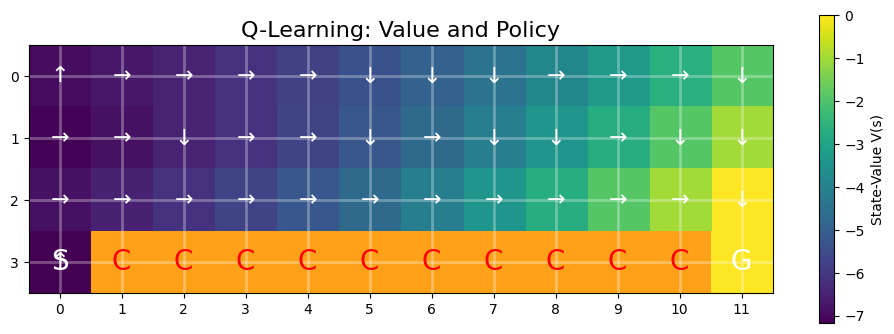

In [49]:
visualize_q_table(q_agent, title="Q-Learning: Value and Policy")

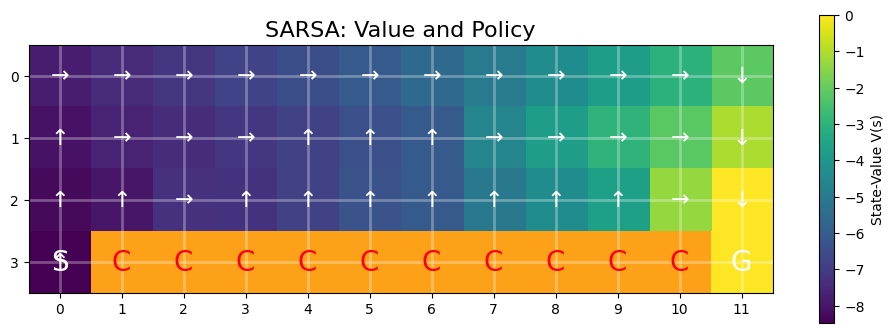

In [50]:
visualize_q_table(sarsa_agent, title="SARSA: Value and Policy")